<a href="https://colab.research.google.com/github/uiu-Rafael/RNA-e-Deep-Learning---CESAR-School-2026.01-A/blob/main/Atividade%202/atividade_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Regressão linear com várias entradas: preços de casas na Califórnia

## Objetivos

- Levar o pipeline do 2.6 (`nn.Linear`, `nn.MSELoss`, `optim.SGD`, `train_epoch`/`validate_epoch`) de **uma** para **oito** variáveis de entrada.
- Separar os dados em treino, validação e teste (70/15/15) e padronizar entradas e saída só com o treino.
- Medir o erro no teste em dólares e compará-lo com um baseline que sempre prevê o preço médio.
- Interpretar os 8 pesos aprendidos.

O dataset **California Housing** vem do censo dos EUA de 1990. Cada linha é um **quarteirão censitário** (*block group*, em geral de 600 a 3.000 moradores), e não uma casa. O alvo é o valor mediano das casas do quarteirão.

Com 8 entradas $x_1, \dots, x_8$, a reta do 2.6 vira um **hiperplano**:

$$\hat{y} = w_0 + w_1 x_1 + w_2 x_2 + \dots + w_8 x_8 = w_0 + \mathbf{x}\,\mathbf{w}^T$$

com $w_0$ = bias e $\mathbf{w} = [w_1, \dots, w_8]$ = pesos. Nos slides: $h_\theta(x) = \theta_0 + \theta_1 x_1 + \dots + \theta_n x_n$.

O que muda em relação ao 2.6:

| | 2.6 (salários) | este notebook |
|---|---|---|
| Entradas | 1 (`YearsExperience`) | 8 |
| Amostras | 30 | 20.640 |
| Modelo | `nn.Linear(1, 1)` | `nn.Linear(8, 1)` |
| Divisão | treino/validação (70/30) | treino/validação/teste (70/15/15) |

## Importação das bibliotecas

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import torch
from torch import nn, optim

torch.manual_seed(1234)
np.random.seed(1234)

## Dados

### Leitura

`fetch_california_housing` baixa o dataset na primeira execução (sem login) e guarda uma cópia em `~/scikit_learn_data`. Com `as_frame=True`, `X` é um `DataFrame` do pandas e `y` é uma `Series`.

In [ ]:
dados = fetch_california_housing(as_frame=True)
X, y = dados.data, dados.target   # 20.640 quarteirões, 8 variáveis; y em centenas de milhares de dólares
print('X:', X.shape, ' y:', y.shape)
X.head()

X: (20640, 8)  y: (20640,)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


### O que cada variável significa

| Variável | Significado | Unidade |
|---|---|---|
| `MedInc` | renda mediana das famílias do quarteirão | dezenas de milhares de dólares por ano (3,87 = US$ 38.700) |
| `HouseAge` | idade mediana das casas | anos |
| `AveRooms` | número médio de cômodos por domicílio | cômodos |
| `AveBedrms` | número médio de quartos por domicílio | quartos |
| `Population` | número de moradores do quarteirão | pessoas |
| `AveOccup` | número médio de moradores por domicílio | pessoas |
| `Latitude` | latitude do quarteirão (maior = mais ao norte) | graus |
| `Longitude` | longitude do quarteirão (maior, ou seja, menos negativa = mais a leste) | graus |
| **`MedHouseVal`** (alvo $y$) | valor mediano das casas do quarteirão | centenas de milhares de dólares de 1990 (2,07 = US$ 207.000) |

In [ ]:
X.describe().T

,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000


In [ ]:
y.describe()

count    20640.000000
mean         2.068558
std          1.153956
min          0.149990
25%          1.196000
50%          1.797000
75%          2.647250
max          5.000010
Name: MedHouseVal, dtype: float64

In [ ]:
print('quarteirões com preço no teto (>= 5,0):', (y >= 5.0).sum())
print('quarteirões com HouseAge no teto (52):  ', (X['HouseAge'] == 52).sum())

# correlação de cada entrada com o preço
dados.frame.corr()['MedHouseVal'].drop('MedHouseVal').sort_values(ascending=False)

quarteirões com preço no teto (>= 5,0): 992
quarteirões com HouseAge no teto (52):   1273


MedInc        0.688075
AveRooms      0.151948
HouseAge      0.105623
AveOccup     -0.023737
Population   -0.024650
Longitude    -0.045967
AveBedrms    -0.046701
Latitude     -0.144160
Name: MedHouseVal, dtype: float64

Algumas observações sobre o `describe()` e as correlações:

- **Escalas muito diferentes:** `Population` vai até ~35 mil, `AveBedrms` fica perto de 1 e `Latitude` está entre 32 e 42. Isso é um motivo para padronizar, como no 2.6.
- **Valores extremos:** `AveRooms` chega a 142, `AveBedrms` a 34 e `AveOccup` a 1.243 moradores por domicílio, contra medianas de 5,2, 1,0 e 2,8. Provavelmente são quarteirões com poucos domicílios e muita gente em alojamentos coletivos, como presídios e dormitórios.
- **Valores cortados no teto:** o preço foi limitado em 5,0 (US$ 500 mil) em 992 quarteirões, e `HouseAge` em 52 anos em 1.273 quarteirões. Para esses quarteirões, o valor verdadeiro é maior que o registrado.
- **Correlação:** `MedInc` é, de longe, a variável mais correlacionada com o preço (0,69). As outras têm correlação individual fraca, mas isso não quer dizer que não ajudam o modelo: a localização, por exemplo, depende da **combinação** de latitude e longitude.

### Gráficos de dispersão contra o preço

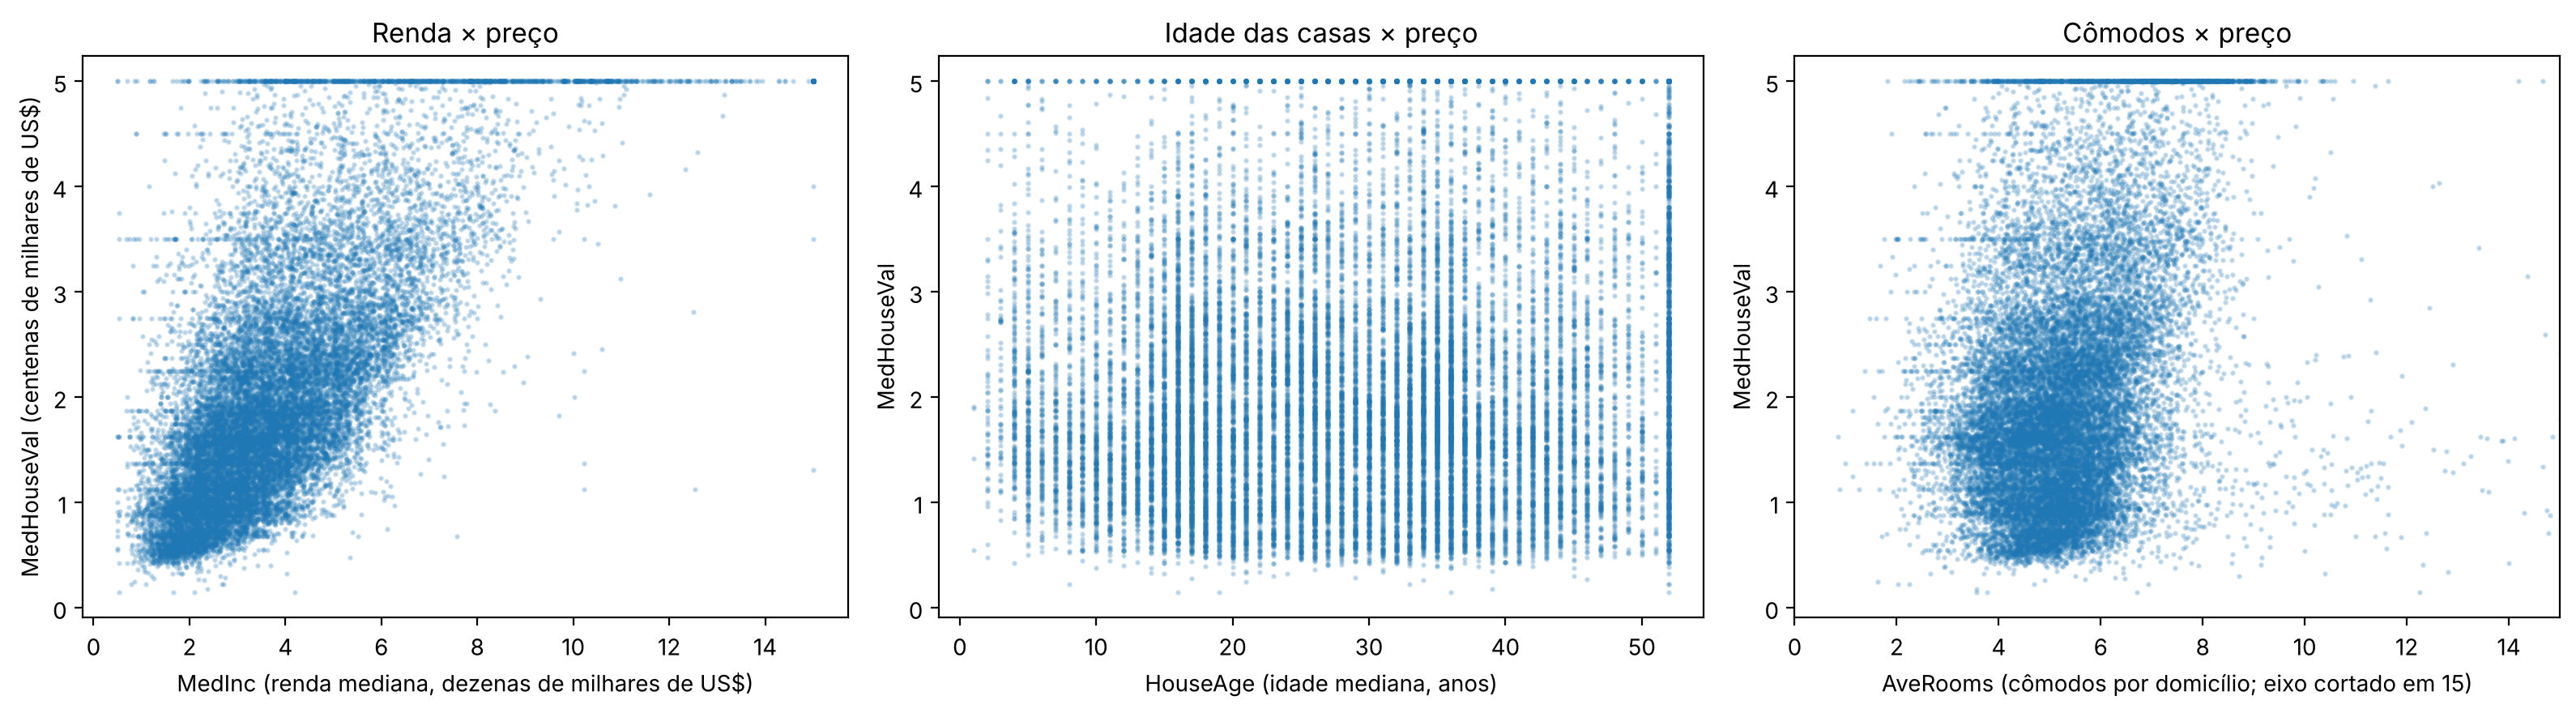

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].scatter(X['MedInc'], y, s=2, alpha=0.2)
axes[0].set_xlabel('MedInc (renda mediana, dezenas de milhares de US$)')
axes[0].set_ylabel('MedHouseVal (centenas de milhares de US$)')
axes[0].set_title('Renda × preço')

axes[1].scatter(X['HouseAge'], y, s=2, alpha=0.2)
axes[1].set_xlabel('HouseAge (idade mediana, anos)')
axes[1].set_ylabel('MedHouseVal')
axes[1].set_title('Idade das casas × preço')

axes[2].scatter(X['AveRooms'], y, s=2, alpha=0.2)
axes[2].set_xlim(0, 15)   # corta os poucos valores extremos (até 142) para ver a nuvem
axes[2].set_xlabel('AveRooms (cômodos por domicílio; eixo cortado em 15)')
axes[2].set_ylabel('MedHouseVal')
axes[2].set_title('Cômodos × preço')

plt.tight_layout()
plt.show()

Latitude e longitude fazem mais sentido juntas: o gráfico abaixo é um mapa da Califórnia, com cada quarteirão colorido pelo preço.

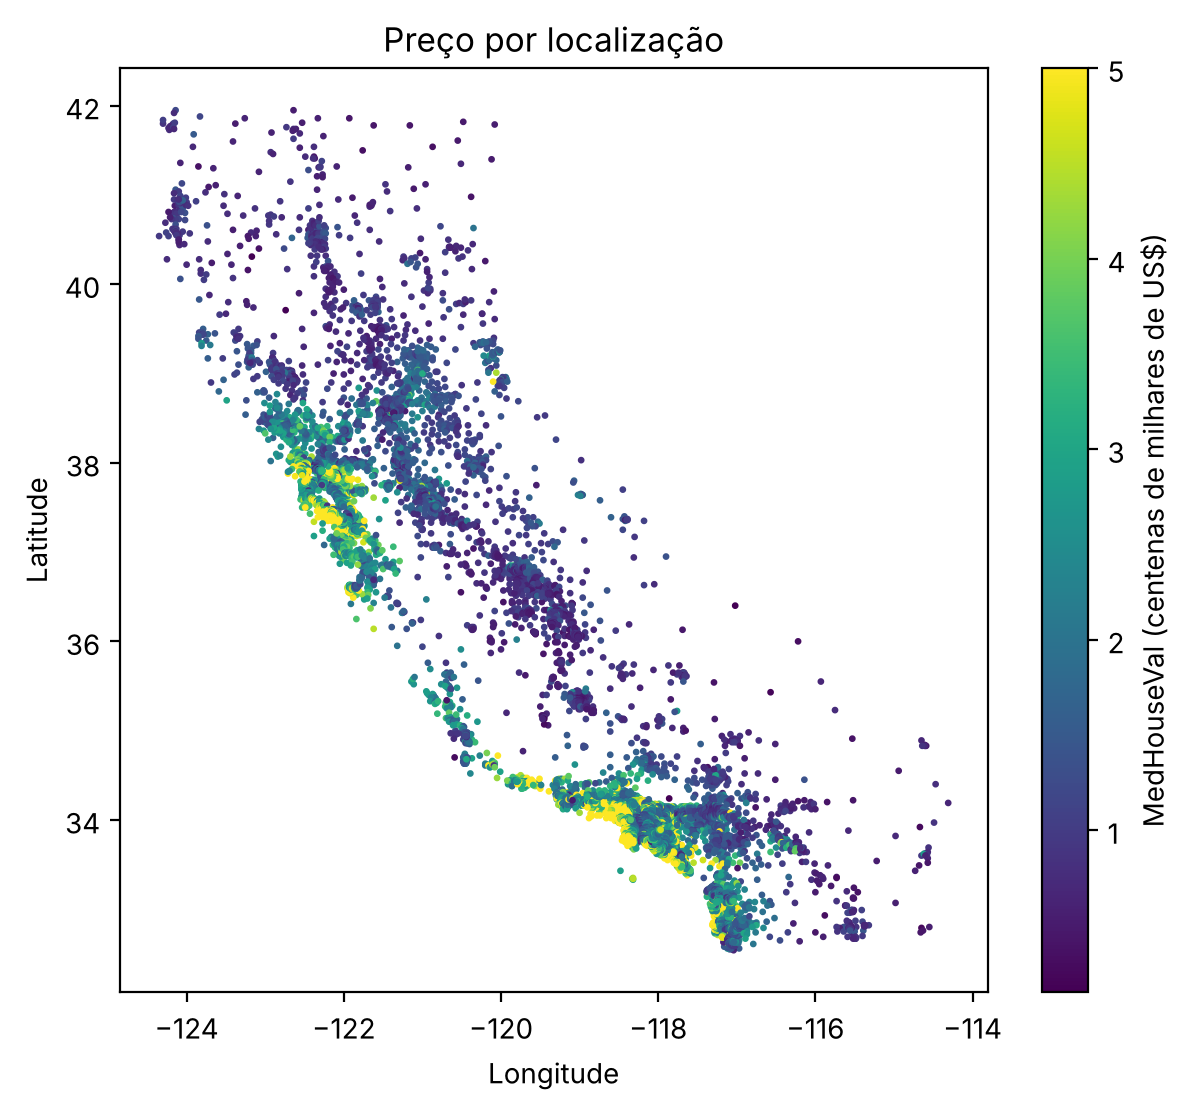

In [ ]:
plt.figure(figsize=(7, 6))
sc = plt.scatter(X['Longitude'], X['Latitude'], c=y, s=2, cmap='viridis')
plt.colorbar(sc, label='MedHouseVal (centenas de milhares de US$)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Preço por localização')
plt.show()

- **Renda × preço:** a relação é a mais forte e aproximadamente linear. Aparece também a linha horizontal em 5,0, onde os preços foram cortados no teto.
- **Idade × preço:** a nuvem é quase sem tendência. A coluna em 52 anos é o teto de `HouseAge`.
- **Cômodos × preço:** há uma tendência fraca, com muita dispersão.
- **Mapa:** os preços mais altos ficam no litoral, nas regiões de São Francisco (≈ 37,8° N, −122,4°) e de Los Angeles e San Diego (≈ 34° N, −118°). O interior e o norte são mais baratos. Essa relação **não é linear** na latitude nem na longitude, o que limita um modelo linear.

### Treino × validação × teste

Com 20 mil amostras, dá para separar três conjuntos:

- **treino (70%)**: ajusta os parâmetros e o `StandardScaler`;
- **validação (15%)**: acompanha o custo durante o treino e serve para escolher hiperparâmetros, como `lr` e `n_epochs`;
- **teste (15%)**: só é usado **uma vez**, no final, para estimar o erro em dados realmente novos.

`train_test_split` é chamado duas vezes: primeiro separa 30% para "validação + teste", depois divide esses 30% ao meio. `random_state=42` fixa os sorteios.

In [ ]:
X_raw = X.to_numpy()                      # (20640, 8)
y_raw = y.to_numpy().reshape(-1, 1)       # (20640, 1)

X_train_raw, X_tmp_raw, y_train_raw, y_tmp_raw = train_test_split(
    X_raw, y_raw, test_size=0.3, random_state=42)
X_val_raw, X_test_raw, y_val_raw, y_test_raw = train_test_split(
    X_tmp_raw, y_tmp_raw, test_size=0.5, random_state=42)

print('treino:   ', X_train_raw.shape, y_train_raw.shape)
print('validação:', X_val_raw.shape, y_val_raw.shape)
print('teste:    ', X_test_raw.shape, y_test_raw.shape)

treino:    (14448, 8) (14448, 1)
validação: (3096, 8) (3096, 1)
teste:     (3096, 8) (3096, 1)


### Padronização

Como no 2.6, cada variável vira $z = (x - \mu)/\sigma$, com $\mu$ e $\sigma$ calculados **só no treino** e depois aplicados à validação e ao teste, para evitar vazamento de dados. O `StandardScaler` das entradas padroniza cada uma das 8 colunas separadamente, com a sua própria média e o seu próprio desvio padrão.

In [ ]:
x_scaler = StandardScaler().fit(X_train_raw)   # 8 médias e 8 desvios padrão
y_scaler = StandardScaler().fit(y_train_raw)

def to_tensor(a):
    return torch.from_numpy(a).float()

x_train = to_tensor(x_scaler.transform(X_train_raw))
y_train = to_tensor(y_scaler.transform(y_train_raw))
x_val = to_tensor(x_scaler.transform(X_val_raw))
y_val = to_tensor(y_scaler.transform(y_val_raw))
x_test = to_tensor(x_scaler.transform(X_test_raw))
y_test = to_tensor(y_scaler.transform(y_test_raw))

print('x_train:', x_train.shape, ' y_train:', y_train.shape)
print('médias no treino (≈ 0):        ', x_train.mean(dim=0).numpy().round(3))
print('desvios padrão no treino (≈ 1):', x_train.std(dim=0).numpy().round(3))

x_train: torch.Size([14448, 8])  y_train: torch.Size([14448, 1])
médias no treino (≈ 0):         [-0. -0.  0.  0.  0. -0. -0.  0.]
desvios padrão no treino (≈ 1): [1. 1. 1. 1. 1. 1. 1. 1.]


## Modelo

`nn.Linear(8, 1)` calcula $\hat{y} = \mathbf{x}\,\mathbf{w}^T + w_0$:

- `model.weight`, shape (1, 8), guarda os 8 pesos $[w_1, \dots, w_8]$, um por variável;
- `model.bias`, shape (1,), é o bias $w_0$.

São 9 parâmetros no total. Como no 2.6, usamos a inicialização padrão do `nn.Linear`.

In [ ]:
model = nn.Linear(8, 1)
print('weight:', model.weight.shape, ' bias:', model.bias.shape)
print('número de parâmetros:', sum(p.numel() for p in model.parameters()))
model(x_train[:3])   # 3 quarteirões -> 3 previsões, shape (3, 1)

weight: torch.Size([1, 8])  bias: torch.Size([1])
número de parâmetros: 9


tensor([[0.3319],
        [0.9249],
        [0.4498]], grad_fn=<AddmmBackward0>)

## Treinamento

### Função de custo, otimizador e taxa de aprendizado

Os mesmos do 2.6. Mas a taxa de aprendizado precisa ser **menor**: lá, com uma só entrada padronizada, o gradiente descendente convergia para qualquer `lr < 1`. Aqui várias entradas são fortemente correlacionadas entre si (`Latitude` com `Longitude`, `AveRooms` com `AveBedrms`), e isso deixa a função de custo mais "estreita" em algumas direções.

O limite de estabilidade é $\text{lr} < 2/\lambda_{max}$, em que $\lambda_{max}$ é o maior autovalor da matriz de derivadas segundas do MSE, $\frac{2}{M} X^T X$ (com a coluna de uns). A célula abaixo calcula esse limite.

In [ ]:
x_bias = torch.cat([torch.ones(x_train.shape[0], 1), x_train], dim=1)   # (M, 9)
H = 2.0 / x_bias.shape[0] * x_bias.t().mm(x_bias)                       # (9, 9)
autovalores = torch.linalg.eigvalsh(H)
print('autovalores:', autovalores.numpy().round(3))
print(f'lr máximo para convergir: 2 / {autovalores.max().item():.3f} = {2 / autovalores.max().item():.3f}')

autovalores: [0.094 0.162 1.316 2.    2.008 2.074 2.55  3.743 4.053]
lr máximo para convergir: 2 / 4.053 = 0.493


O gradiente descendente diverge com `lr` acima de ~0,49. Usamos `lr = 0.3`, com margem de segurança. O menor autovalor (~0,09) define a direção mais lenta de convergência: ela encolhe por um fator de $(1 - 0{,}3 \times 0{,}09) \approx 0{,}97$ por época, então são necessárias algumas centenas de épocas.

In [ ]:
lr = 0.3
n_epochs = 300
criterion = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr=lr)   # atualiza weight (8 pesos) e bias

### Funções de treino e de validação

As mesmas do 2.6: cada época é um passo de gradiente descendente com todo o treino (14.448 amostras de uma vez).

In [ ]:
def train_epoch(model, optimizer, criterion, x_train, y_train):
    model.train()
    optimizer.zero_grad()
    y_pred = model(x_train)
    loss = criterion(y_pred, y_train)
    loss.backward()
    optimizer.step()
    return loss.item()


def validate_epoch(model, criterion, x_val, y_val):
    model.eval()
    with torch.no_grad():
        y_pred = model(x_val)
        loss = criterion(y_pred, y_val)
    return loss.item()

### Laço de treinamento

In [ ]:
train_losses = []
val_losses = []

for epoch in range(n_epochs):
    train_loss = train_epoch(model, optimizer, criterion, x_train, y_train)
    train_losses.append(train_loss)

    val_loss = validate_epoch(model, criterion, x_val, y_val)
    val_losses.append(val_loss)

    if (epoch + 1) % 50 == 0:
        print(f'Epoch[{epoch + 1}/{n_epochs}], Train Loss: {train_loss:.6f}, Val Loss: {val_loss:.6f}')

Epoch[50/300], Train Loss: 0.391290, Val Loss: 0.404290
Epoch[100/300], Train Loss: 0.390662, Val Loss: 0.403759
Epoch[150/300], Train Loss: 0.390654, Val Loss: 0.403737
Epoch[200/300], Train Loss: 0.390654, Val Loss: 0.403732
Epoch[250/300], Train Loss: 0.390654, Val Loss: 0.403730
Epoch[300/300], Train Loss: 0.390654, Val Loss: 0.403730


### Curvas de custo de treino e de validação

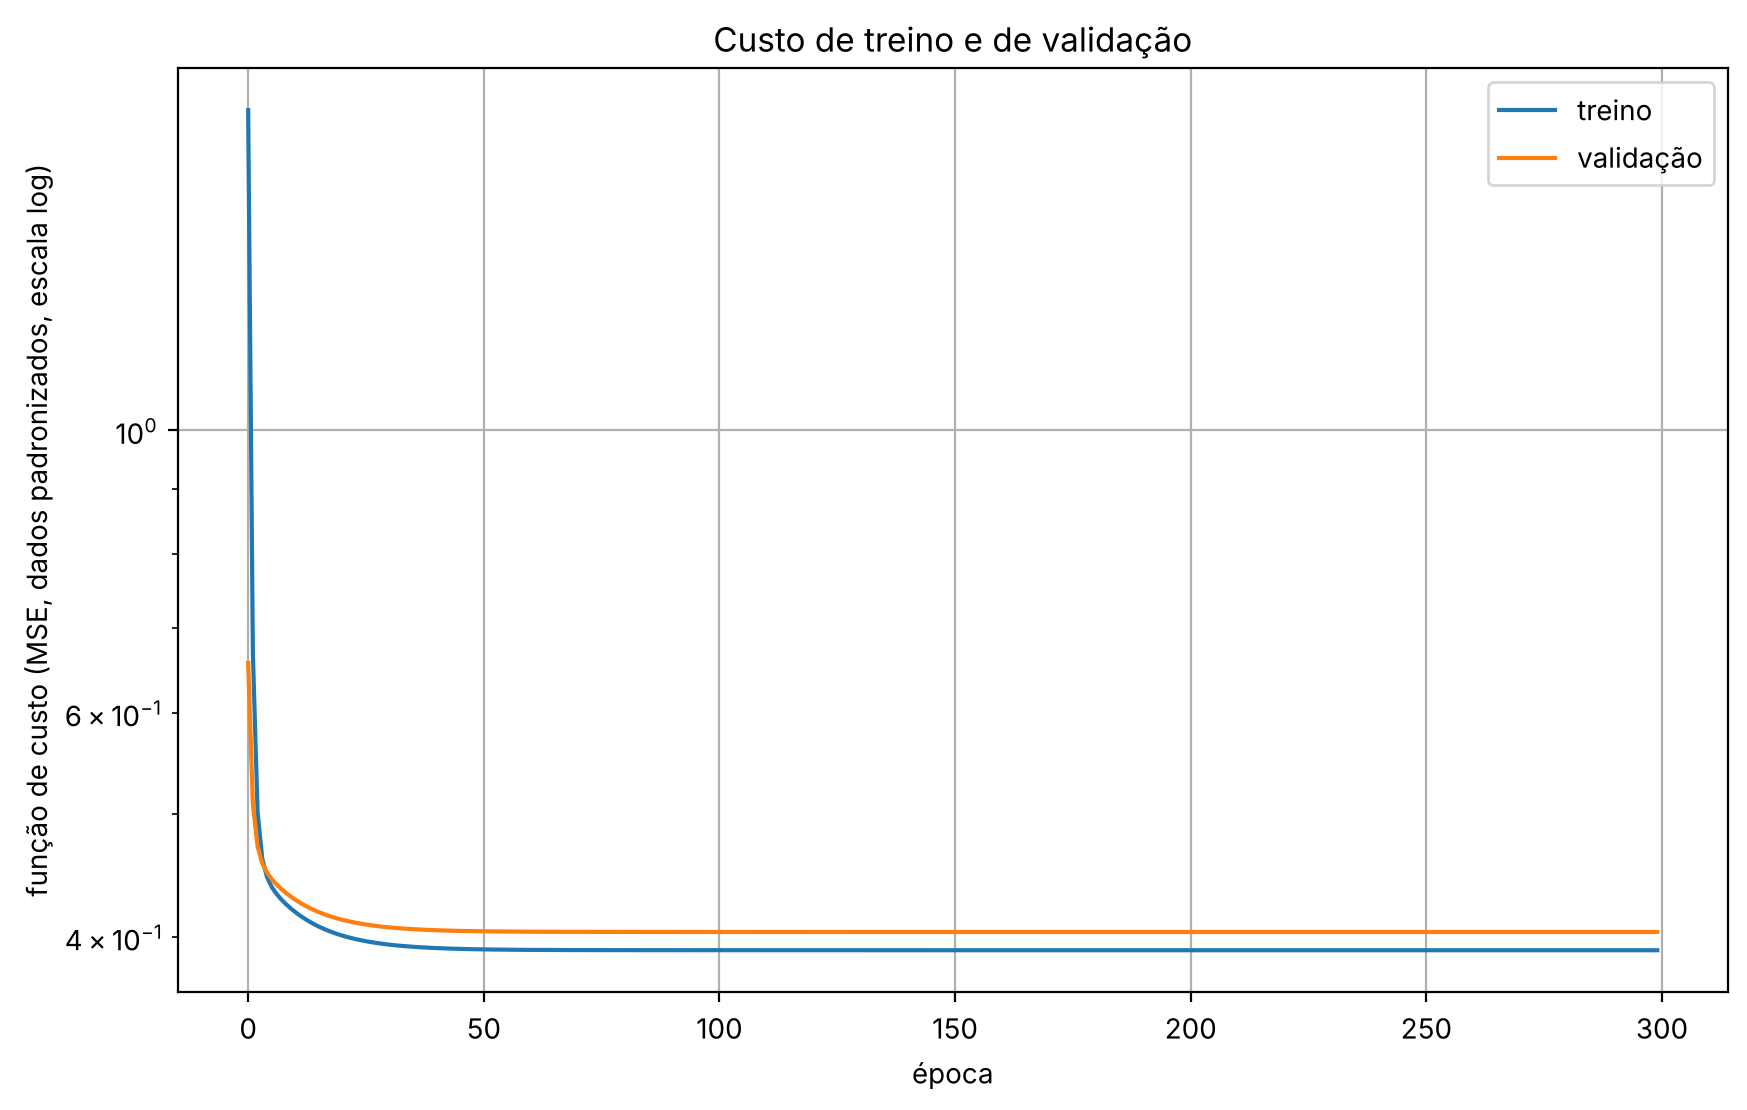

In [ ]:
plt.figure(figsize=(10, 6))
plt.plot(range(n_epochs), train_losses, label='treino')
plt.plot(range(n_epochs), val_losses, label='validação')
plt.yscale('log')
plt.xlabel('época')
plt.ylabel('função de custo (MSE, dados padronizados, escala log)')
plt.title('Custo de treino e de validação')
plt.legend()
plt.grid(True)
plt.show()

As duas curvas caem rápido nas primeiras ~20 épocas e ficam estáveis a partir de ~100 épocas: o treino convergiu. (Na época 0, a validação aparece abaixo do treino só porque o custo de treino é medido antes do `step()` e o de validação depois dele, como no 2.6.)

O custo final de validação (≈ 0,404) é só um pouco maior que o de treino (≈ 0,391). Com 9 parâmetros e 14 mil amostras, não há overfitting. O problema deste modelo é o contrário: **underfitting**. Mesmo no treino, o erro continua alto, porque uma reta (hiperplano) não consegue representar a relação entre as variáveis e o preço.

### Conferência com a solução analítica

Como nos notebooks anteriores, a equação normal $w^* = (X^T X)^{-1} X^T y$, com a coluna de uns e os dados de treino, dá os parâmetros ótimos. O modelo treinado deve ficar muito próximo deles.

In [ ]:
w_opt = torch.linalg.solve(x_bias.t().mm(x_bias), x_bias.t().mm(y_train))   # (9, 1): [w0, w1..w8]
w_trained = torch.cat([model.bias.detach(), model.weight.detach().flatten()])
print('analítico:', w_opt.flatten().numpy().round(4))
print('treinado: ', w_trained.numpy().round(4))
print(f'maior diferença: {(w_trained - w_opt.flatten()).abs().max().item():.1e}')

analítico: [-0.      0.7337  0.1055 -0.2588  0.301  -0.0008 -0.036  -0.7723 -0.7505]
treinado:  [ 0.      0.7337  0.1055 -0.2588  0.301  -0.0008 -0.036  -0.7722 -0.7504]
maior diferença: 1.7e-05


## Avaliação no teste

### RMSE em dólares e baseline

O teste é usado agora, uma única vez. As previsões são levadas de volta à unidade original com `y_scaler.inverse_transform` (centenas de milhares de dólares) e multiplicadas por 100.000 para virar dólares.

O **baseline** é o modelo mais simples possível: prever sempre o preço médio do **treino**, sem olhar as entradas. Um modelo só é útil se errar menos que ele.

Também calculamos o $R^2 = 1 - \text{MSE}_{modelo} / \text{MSE}_{baseline}$: a fração da variação do preço que o modelo explica (0 = igual ao baseline, 1 = perfeito).

In [ ]:
model.eval()
with torch.no_grad():
    y_test_pred = model(x_test)

y_test_pred_raw = y_scaler.inverse_transform(y_test_pred.numpy())   # centenas de milhares de US$

rmse_test = np.sqrt(np.mean((y_test_pred_raw - y_test_raw) ** 2)) * 100_000
rmse_baseline = np.sqrt(np.mean((y_train_raw.mean() - y_test_raw) ** 2)) * 100_000
r2_test = 1 - (rmse_test / rmse_baseline) ** 2

print(f'preço médio no treino:          US$ {y_train_raw.mean() * 100_000:,.0f}')
print(f'RMSE no teste - modelo linear:  US$ {rmse_test:,.0f}')
print(f'RMSE no teste - baseline média: US$ {rmse_baseline:,.0f}')
print(f'redução do erro: {1 - rmse_test / rmse_baseline:.1%}   R² no teste: {r2_test:.3f}')

preço médio no treino:          US$ 206,924
RMSE no teste - modelo linear:  US$ 72,129
RMSE no teste - baseline média: US$ 114,992
redução do erro: 37.3%   R² no teste: 0.607


### Previsto × real no teste

Num modelo perfeito, todos os pontos ficariam sobre a diagonal tracejada.

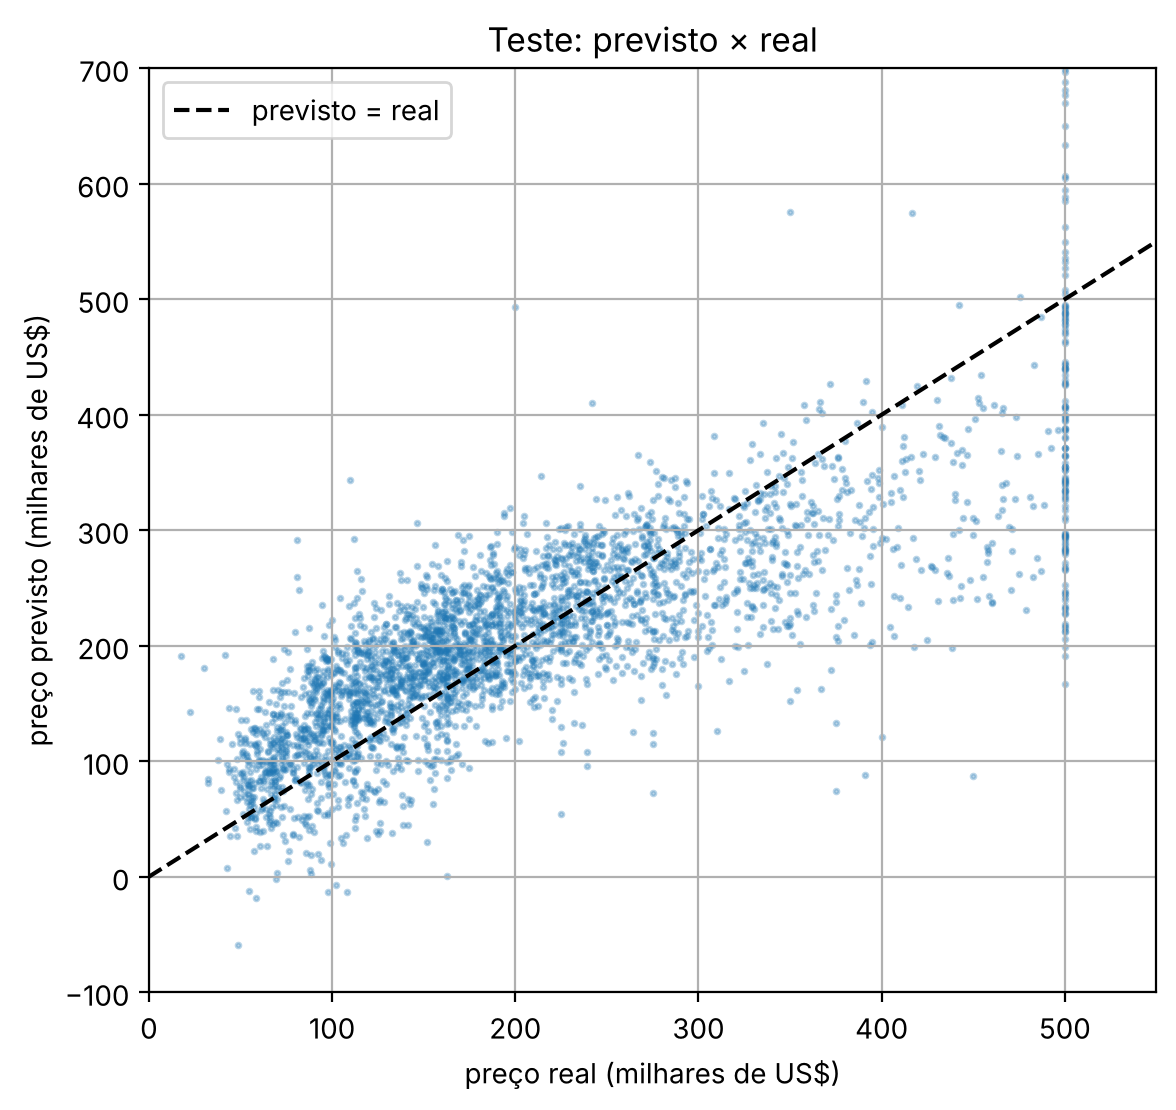

previsões negativas no teste:               7
previsões acima de US$ 700 mil (fora do eixo): 2
RMSE nos 141 quarteirões com preço no teto: US$ 164,478
RMSE nos outros 2955 quarteirões:         US$ 64,498


In [ ]:
plt.figure(figsize=(6.5, 6))
plt.scatter(y_test_raw * 100, y_test_pred_raw * 100, s=3, alpha=0.3)
lim = [-100, 700]
plt.plot(lim, lim, 'k--', label='previsto = real')
plt.xlim(0, 550)
plt.ylim(-100, 700)
plt.xlabel('preço real (milhares de US$)')
plt.ylabel('preço previsto (milhares de US$)')
plt.title('Teste: previsto × real')
plt.legend()
plt.grid(True)
plt.show()

print('previsões negativas no teste:              ', (y_test_pred_raw < 0).sum())
print('previsões acima de US$ 700 mil (fora do eixo):', (y_test_pred_raw > 7).sum())

# erro separado: quarteirões com preço no teto (5,0) × os demais
teto = y_test_raw.flatten() >= 5.0
rmse_teto = np.sqrt(np.mean((y_test_pred_raw[teto] - y_test_raw[teto]) ** 2)) * 100_000
rmse_resto = np.sqrt(np.mean((y_test_pred_raw[~teto] - y_test_raw[~teto]) ** 2)) * 100_000
print(f'RMSE nos {teto.sum()} quarteirões com preço no teto: US$ {rmse_teto:,.0f}')
print(f'RMSE nos outros {(~teto).sum()} quarteirões:         US$ {rmse_resto:,.0f}')

O gráfico mostra três limitações do modelo linear:

- **Teto de US$ 500 mil:** a coluna vertical em 500 são os quarteirões cortados no teto. O preço verdadeiro deles é maior, e o modelo prevê qualquer coisa entre ~170 e mais de 700 mil. Sozinhos, esses quarteirões têm RMSE de ~US$ 164 mil, mais que o dobro do restante (~US$ 64 mil).
- **Viés nos extremos:** abaixo de ~US$ 150 mil, o modelo tende a prever **acima** do real. Acima de ~US$ 350 mil, tende a prever **abaixo**. A nuvem é mais "deitada" que a diagonal, que é o sinal típico de uma relação não linear ajustada por uma reta.
- **Previsões impossíveis:** algumas previsões são negativas e outras passam de US$ 1 milhão. Um modelo linear não tem limites na saída: valores extremos de `AveOccup`, `AveRooms` ou `AveBedrms` levam a previsão para muito longe.

## Os 8 pesos aprendidos

Com as entradas e a saída padronizadas, cada peso $w_j$ responde à pergunta: se a variável $j$ aumenta **1 desvio padrão** e as outras 7 ficam fixas, quantos desvios padrão o preço previsto muda?

Para comparar, a última coluna da tabela converte cada peso para a unidade original, $w_j \cdot \sigma_y / \sigma_{x_j}$, em dólares por unidade da variável.

In [ ]:
pesos = pd.DataFrame({
    'peso (padronizado)': model.weight.detach().numpy().flatten(),
    'desvio padrão da variável': x_scaler.scale_,
}, index=X.columns)
# efeito de +1 unidade original da variável, em dólares
pesos['US$ por +1 unidade'] = pesos['peso (padronizado)'] * y_scaler.scale_[0] / x_scaler.scale_ * 100_000
pesos = pesos.sort_values('peso (padronizado)', ascending=False)
pesos.round(3)

,peso (padronizado),desvio padrão da variável,US$ por +1 unidade
MedInc,0.734,1.905,44582.704
AveBedrms,0.301,0.447,77862.895
HouseAge,0.106,12.613,968.200
Population,-0.001,1140.186,-0.078
AveOccup,-0.036,12.373,-337.006
AveRooms,-0.259,2.453,-12210.161
Longitude,-0.750,2.003,-43367.879
Latitude,-0.772,2.136,-41852.761


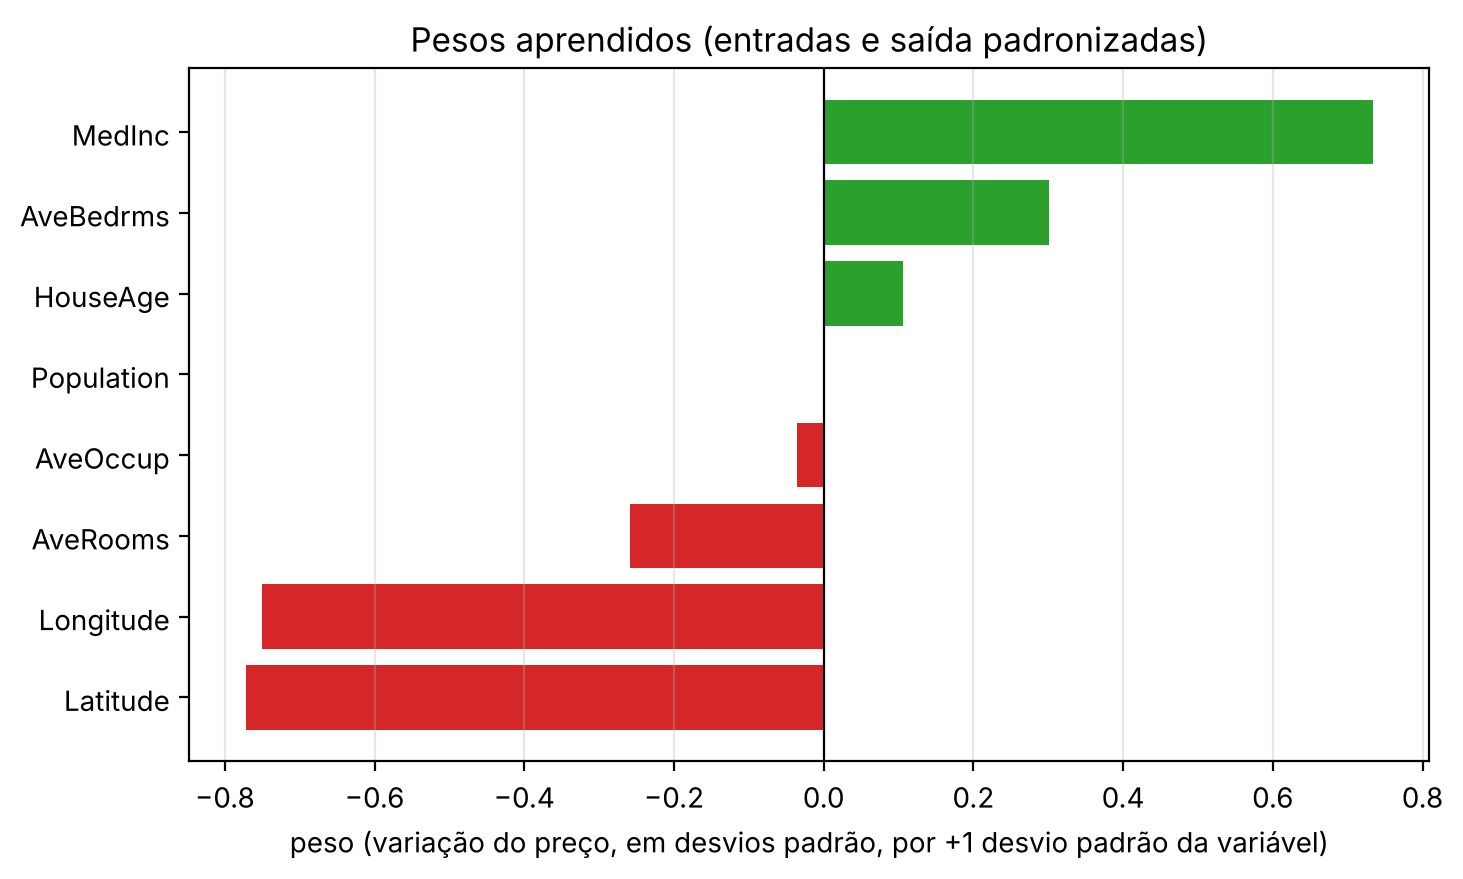

bias w0: 1.1e-08  (≈ 0, porque x e y têm média zero no treino, como no 2.6)


In [ ]:
cores = ['tab:green' if w > 0 else 'tab:red' for w in pesos['peso (padronizado)']]
plt.figure(figsize=(8, 4.5))
plt.barh(pesos.index, pesos['peso (padronizado)'], color=cores)
plt.axvline(0, color='k', linewidth=0.8)
plt.gca().invert_yaxis()
plt.xlabel('peso (variação do preço, em desvios padrão, por +1 desvio padrão da variável)')
plt.title('Pesos aprendidos (entradas e saída padronizadas)')
plt.grid(axis='x', alpha=0.3)
plt.show()

print(f'bias w0: {model.bias.item():.1e}  (≈ 0, porque x e y têm média zero no treino, como no 2.6)')

**O que mais aumenta o preço previsto** (pesos positivos):

1. **`MedInc`** (+0,73): é o maior peso positivo, e coincide com a variável mais correlacionada com o preço. Quarteirões de renda mais alta têm casas mais caras.
2. **`AveBedrms`** (+0,30): mais quartos por domicílio, *com o número de cômodos fixo*.
3. **`HouseAge`** (+0,11): efeito pequeno. Uma explicação provável é que casas mais antigas ficam nos bairros mais antigos e centrais das cidades.

**O que mais diminui o preço previsto** (pesos negativos):

1. **`Latitude`** (−0,77) e **`Longitude`** (−0,75): ir para o **norte** ou para o **leste** diminui o preço. Como na Califórnia o litoral corre de noroeste para sudeste, os dois pesos juntos dizem "longe do litoral = mais barato", o que bate com o mapa.
2. **`AveRooms`** (−0,26): mais cômodos por domicílio, *com o número de quartos fixo*.
3. `AveOccup` (−0,04) e `Population` (≈ 0) quase não influenciam.

**Cuidado ao interpretar.** Cada peso mede o efeito de uma variável **mantendo as outras fixas**, e algumas variáveis são muito correlacionadas entre si:

- `AveRooms` × `AveBedrms`: correlação de 0,85 no treino;
- `Latitude` × `Longitude`: correlação de −0,92 no treino.

Por isso, `AveRooms` tem peso negativo, embora sozinha tenha correlação **positiva** com o preço (+0,15). O modelo usa o par: "mais cômodos que não são quartos" e "mais quartos para o mesmo número de cômodos" se compensam. Da mesma forma, os pesos grandes e de mesmo sinal de latitude e longitude só fazem sentido juntos. Com variáveis correlacionadas, o peso de cada uma isoladamente pode ser enganoso.

**Por que só faz sentido comparar os pesos porque as entradas foram padronizadas?** Um peso é "quanto o preço muda por **uma unidade** da variável", e as unidades são muito diferentes: 1 pessoa de `Population`, 1 ano de `HouseAge`, US$ 10 mil de `MedInc`, 1 grau de latitude. Com os dados originais, o tamanho do peso dependeria da unidade escolhida. A última coluna da tabela mostra isso: em dólares por unidade, `AveBedrms` (+US$ 78 mil por quarto) parece mais importante que `MedInc` (+US$ 45 mil por US$ 10 mil de renda), e `Population` parece irrelevante (−US$ 0,08 por pessoa). Mas um quarto a mais por domicílio é uma variação enorme (o desvio padrão é 0,45 quarto), e mil pessoas a mais é uma variação comum.

Depois da padronização, todas as entradas têm desvio padrão 1, e cada peso passa a medir o efeito de uma variação **típica** da variável (1 desvio padrão). Assim, todos estão na mesma escala, sem unidade, e o tamanho do peso pode ser comparado entre as variáveis. O sinal do peso, por outro lado, não depende da padronização.

## Conclusão

**O modelo é bom o suficiente?** Ele é claramente melhor que não ter modelo: o RMSE no teste caiu de ~US$ 115 mil (baseline) para ~US$ 72 mil, e o modelo explica ~61% da variação do preço ($R^2 \approx 0{,}61$). Mas, para avaliar o preço de um quarteirão, um erro típico de US$ 72 mil, num preço médio de ~US$ 207 mil (≈ 35%), é grande demais. Além disso, o modelo dá previsões impossíveis (negativas ou acima de US$ 1 milhão) e erra sistematicamente nos extremos. Como os custos de treino e de validação são parecidos, o limite não é a falta de dados nem o overfitting: é o próprio **modelo linear**, que não captura relações não lineares como o efeito da localização (underfitting).

**O que tentar para melhorar:**

1. **Um modelo não linear:** uma rede neural com camadas ocultas e ativação não linear (o próximo passo do curso: basta trocar `nn.Linear(8, 1)` por uma sequência de camadas, mantendo todo o resto do pipeline) ou árvores de decisão com boosting.
2. **Novas variáveis (feature engineering):** distância até São Francisco e Los Angeles, ou até o litoral, em vez de latitude e longitude cruas; razões como quartos por cômodo; logaritmo das variáveis muito assimétricas (`Population`, `AveOccup`, `MedInc`).
3. **Tratar os valores extremos:** limitar (*clip*) ou remover os quarteirões com `AveRooms`, `AveBedrms` e `AveOccup` absurdos, e decidir o que fazer com os 992 preços cortados no teto (remover do treino ou usar um modelo que trate a saída como limitada).
4. **Prever o logaritmo do preço:** erros relativos fazem mais sentido para preços, e isso também evita previsões negativas.
5. **Mini-batches** (3.3) para treinar mais rápido em datasets maiores. Com um modelo maior, regularização e *early stopping* guiado pela curva de validação.